# 06 — Analisis Statistik Q1, Kalibrasi Probabilitas, DCA, Subgrup Klinis, & Rekap Master

Notebook ini (pure CPU, membaca output OOF dari `01`–`04`) menghasilkan paket bukti statistik lengkap dan berintegritas untuk target jurnal Q1/Q2:
1. **Bagian 1:** Audit empiris tantangan dataset Regensburg ($N=578$): ketimpangan kelas, tingkat *missingness*, fraksi *single-view* ($K=1$), overlap CRP/Alvarado, & visibilitas apendiks.
2. **Bagian 2:** Rekap master seluruh eksperimen (`01` + `02` + `03` + `04`).
3. **Bagian 3:** Uji signifikansi berpasangan (**Paired Stratified Bootstrap $B=5000$** + **Exact McNemar Test**), termasuk uji stratum $K$ tetap untuk membuktikan `Cross-Attention > MV-LSTM`.
4. **Bagian 4:** Kalibrasi probabilitas (**Brier Score**, **10-bin ECE**, Reliability Diagram) & **Decision Curve Analysis (DCA)** untuk *clinical net benefit*.
5. **Bagian 5:** Analisis subgrup klinis (*Alvarado*, *PAS*, *Appendix_on_US*, usia, jenis kelamin, panjang bag) & audit ketidaksepakatan (*disagreement/error analysis*).
6. **Bagian 6:** Laporan integritas terstruktur (`06_q1_integrity_master_report.txt`) lengkap dengan poin limitasi jujur tanpa overklaim.


In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss

candidates = [Path.cwd(), *Path.cwd().parents]
PM3_DIR = next(
    (p if (p / "pm3_data.py").is_file() else p / "Proposed Model 3")
    for p in candidates
    if (p / "pm3_data.py").is_file() or (p / "Proposed Model 3" / "pm3_data.py").is_file()
)
ROOT_DIR = PM3_DIR.parent
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

from pm3_data import (
    ClinicalPipeline,
    CONCEPTS_PM3,
    FEATURES,
    images_by_patient,
    load_cohort,
    make_stratified_folds,
)
from pm3_train import calibrate_thresholds_nested_oof, compute_metrics

RUNS_DIR = PM3_DIR / "runs"
OUT_DIR = RUNS_DIR / "06_q1_statistical_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_BACKBONE = "stage7_only"

cohort = load_cohort(ROOT_DIR / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT_DIR / "image_manifest_filtered.csv")
manifest["image_id"] = manifest["image_id"].astype(str)
manifest = manifest.loc[manifest["US_Number"].isin(cohort.index)].copy().reset_index(drop=True)
folds = make_stratified_folds(cohort, seed=1, n_splits=5)
bags_all = images_by_patient(manifest, bag_mode="all")

# Rekonstruksi identik OOF B1 clean_28 (seed=42 seperti pm3_baselines.py) untuk uji statistik berpasangan
fold_xy = []
for f in folds:
    tr_df = cohort.loc[f["train"]]
    va_df = cohort.loc[f["val"]]
    pipe = ClinicalPipeline().fit(tr_df)
    fold_xy.append({
        "fold": f["fold"],
        "pids": va_df.index.to_numpy(int),
        "X_tr": pipe.transform(tr_df),
        "y_tr": tr_df["label"].to_numpy(int),
        "X_va": pipe.transform(va_df),
        "y_va": va_df["label"].to_numpy(int),
    })

def build_hier_tabular_oof(factory):
    rows = []
    for fd in fold_xy:
        c_diag = factory().fit(fd["X_tr"], (fd["y_tr"] > 0).astype(int))
        m_app = fd["y_tr"] > 0
        c_comp = factory().fit(fd["X_tr"][m_app], (fd["y_tr"][m_app] == 2).astype(int))
        pd_ = c_diag.predict_proba(fd["X_va"])[:, 1]
        qc_ = c_comp.predict_proba(fd["X_va"])[:, 1]
        for pid, yt, p, q in zip(fd["pids"], fd["y_va"], pd_, qc_):
            rows.append({
                "patient_id": int(pid), "fold": fd["fold"], "label": int(yt),
                "p_diag": float(p), "q_comp": float(q),
                "p_0": float(1.0 - p), "p_1": float(p * (1.0 - q)), "p_2": float(p * q),
                "pred": int(0 if p < 0.5 else (1 if q < 0.5 else 2)),
            })
    df_oof = pd.DataFrame(rows)
    df_oof, m_cal = calibrate_thresholds_nested_oof(df_oof, "hierarchical")
    return df_oof.sort_values("patient_id").reset_index(drop=True), m_cal

def build_binary_tabular_oof(factory, task_mode: str):
    rows = []
    y_fn = (lambda y: (y > 0).astype(int)) if task_mode == "binary_diag" else (lambda y: (y == 2).astype(int))
    for fd in fold_xy:
        clf = factory().fit(fd["X_tr"], y_fn(fd["y_tr"]))
        pr = clf.predict_proba(fd["X_va"])[:, 1]
        yv = y_fn(fd["y_va"])
        for pid, yt, p in zip(fd["pids"], yv, pr):
            rows.append({
                "patient_id": int(pid), "fold": fd["fold"], "label": int(yt),
                "prob": float(p), "p_0": float(1.0 - p), "p_1": float(p),
                "pred": int(p >= 0.5),
            })
    df_oof = pd.DataFrame(rows)
    df_oof, m_cal = calibrate_thresholds_nested_oof(df_oof, task_mode)
    return df_oof.sort_values("patient_id").reset_index(drop=True), m_cal

rf_factory = lambda: RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42)
lr_factory = lambda: LogisticRegression(max_iter=1500, class_weight="balanced", C=0.5, random_state=42)

b1_hier_rf_oof, m_rf_h = build_hier_tabular_oof(rf_factory)
b1_hier_lr_oof, m_lr_h = build_hier_tabular_oof(lr_factory)
b1_diag_rf_oof, m_rf_d = build_binary_tabular_oof(rf_factory, "binary_diag")
b1_sev_rf_oof, m_rf_s = build_binary_tabular_oof(rf_factory, "binary_sev")

b1_hier_rf_oof.to_csv(OUT_DIR / "b1_hier_rf_oof_predictions.csv", index=False)
print(f"Rekonstruksi B1 Hier_RF_balanced OK: AUROC={m_rf_h['multiclass_auroc']:.4f} | MacroF1={m_rf_h['macro_f1']:.4f}")
print(f"Rekonstruksi B1 RF binary_diag   OK: AUROC={m_rf_d['auroc']:.4f} | F1={m_rf_d['f1']:.4f}")
print(f"Rekonstruksi B1 RF binary_sev    OK: AUROC={m_rf_s['auroc']:.4f} | F1={m_rf_s['f1']:.4f}")

def load_oof(run_dir_name: str):
    p = RUNS_DIR / run_dir_name / "oof_predictions.csv"
    if not p.exists():
        return None
    df = pd.read_csv(p).sort_values("patient_id").reset_index(drop=True)
    if "pred_calibrated" not in df.columns:
        df["pred_calibrated"] = df["pred"]
    return df


Rekonstruksi B1 Hier_RF_balanced OK: AUROC=0.7937 | MacroF1=0.6414
Rekonstruksi B1 RF binary_diag   OK: AUROC=0.8018 | F1=0.8270
Rekonstruksi B1 RF binary_sev    OK: AUROC=0.8804 | F1=0.6010


=== 01_dataset_challenges_audit.csv ===
Top 10 missing rates di 28 clean clinical features (%):
RBC_in_Urine                      25.43
Ketones_in_Urine                  25.26
WBC_in_Urine                      25.09
Ipsilateral_Rebound_Tenderness    23.18
Neutrophil_Percentage             13.67
Neutrophilia                       6.57
Psoas_Sign                         4.33
Dysuria                            3.81
BMI                                3.63
Height                             3.46

Ketersediaan & prevalensi 8 Konsep Sonografis:


,group,n_patients,pct_cohort,bag_len_mean,bag_len_median,pct_single_view_K1,bag_len_max,crp_median,crp_iqr,wbc_median,wbc_iqr,alvarado_median,alvarado_iqr,pas_median,pas_iqr,appendix_visible_on_us_pct
0,0_No_Appendicitis,196,33.91,1.95,1.0,55.10,11,1.0,9.0,8.75,4.90,5.0,3.0,4.0,3.0,58.67
1,1_Uncomplicated,286,49.48,3.84,3.0,13.29,15,8.5,24.0,13.00,6.28,6.0,3.0,6.0,3.0,91.61
2,2_Complicated,96,16.61,2.71,2.0,34.38,11,75.5,138.5,17.70,6.10,8.0,2.0,6.0,2.0,64.58


,concept,n_valid,n_positive,missing_or_unrecorded_pct,prevalence_among_valid_pct,auroc,f1
0,Appendix_Diameter,434,335,24.913,77.189,0.728,0.824
1,Appendix_Wall_Layers,194,79,66.436,40.722,0.686,0.555
2,Appendix_on_US,575,439,0.519,76.348,0.683,0.858
3,Free_Fluids,578,251,0.000,43.426,0.592,0.533
4,Pathological_Lymph_Nodes,578,135,0.000,23.356,0.648,0.432
5,Severe_Complication_Signs,578,96,0.000,16.609,0.662,0.362
6,Surrounding_Tissue_Reaction,578,188,0.000,32.526,0.629,0.496
7,Target_Sign,578,75,0.000,12.976,0.510,0.175


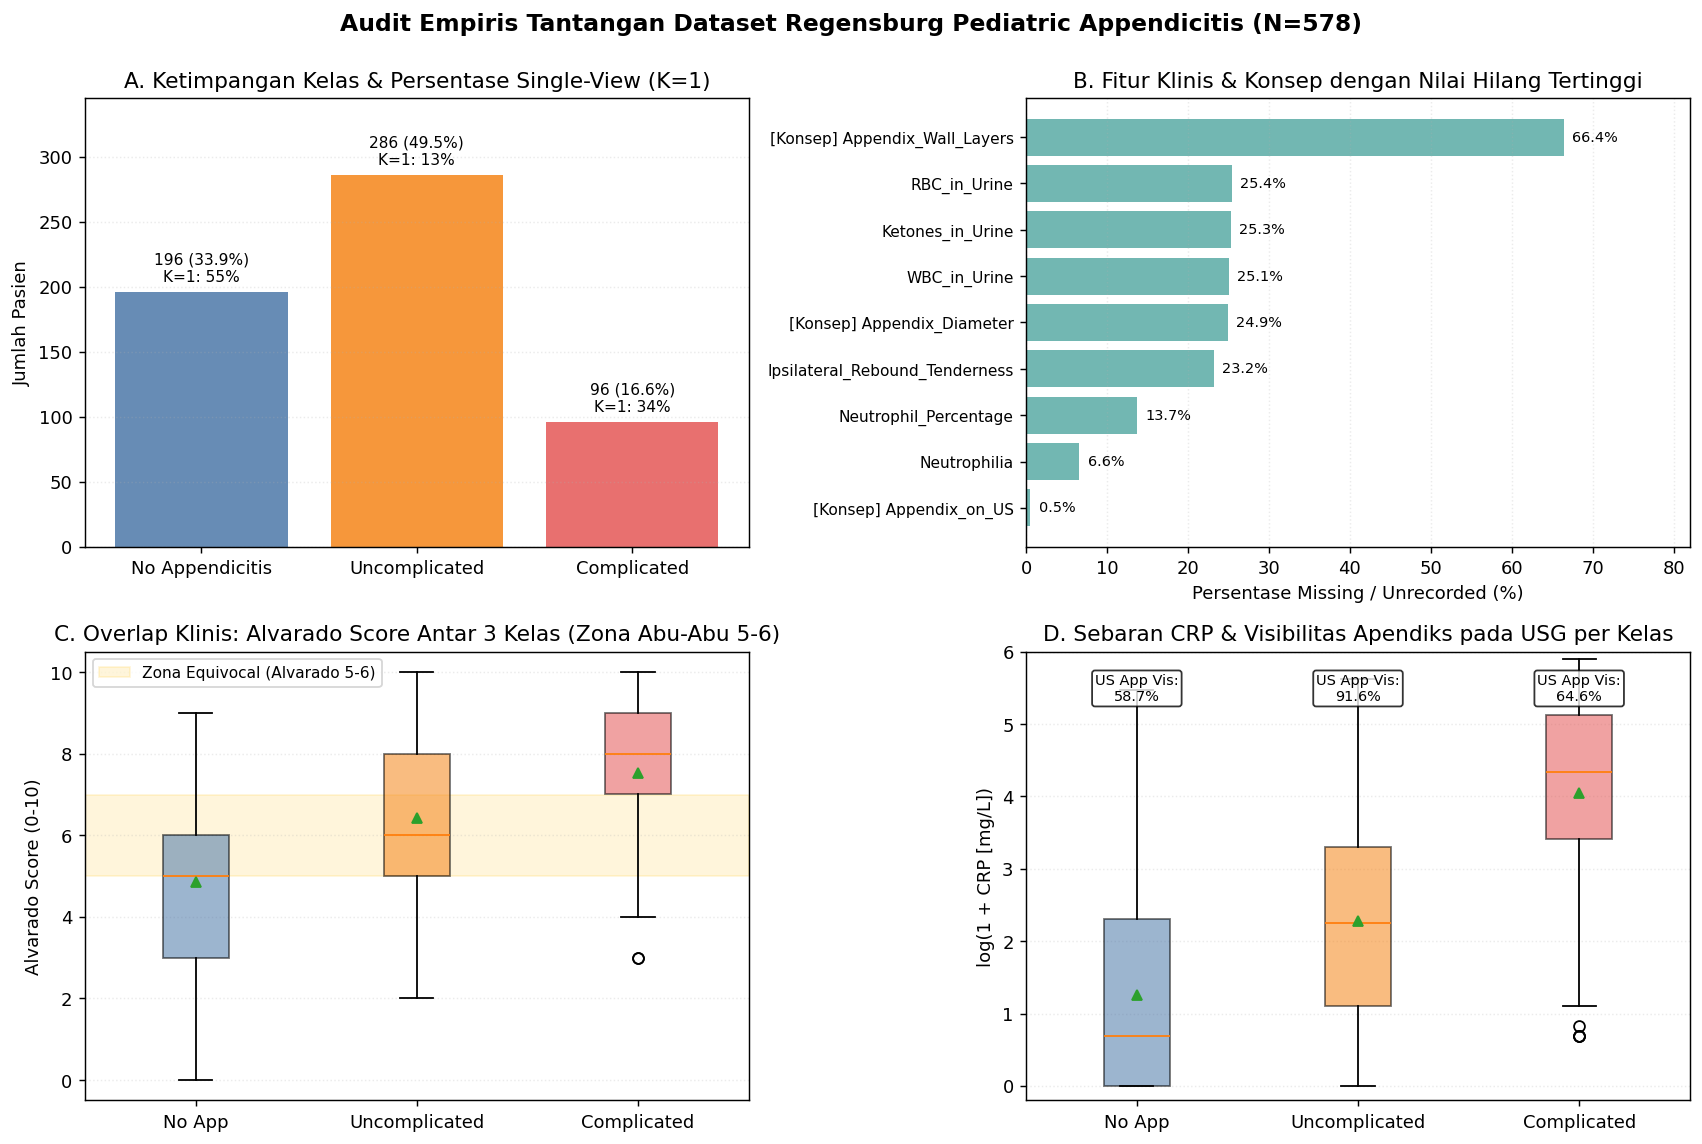

In [2]:
# ==================== BAGIAN 1: AUDIT EMPIRIS TANTANGAN DATASET (N=578) ====================
challenge_rows = []
counts = cohort["label"].value_counts().sort_index()
total_n = len(cohort)
for c, cname in [(0, "0_No_Appendicitis"), (1, "1_Uncomplicated"), (2, "2_Complicated")]:
    sub = cohort.loc[cohort["label"] == c]
    bag_sizes = [len(bags_all[int(pid)]) for pid in sub.index]
    crp_med, crp_iqr = float(sub["CRP"].median()), float(sub["CRP"].quantile(0.75) - sub["CRP"].quantile(0.25))
    wbc_med, wbc_iqr = float(sub["WBC_Count"].median()), float(sub["WBC_Count"].quantile(0.75) - sub["WBC_Count"].quantile(0.25))
    alv_med, alv_iqr = float(sub["Alvarado_Score"].median()), float(sub["Alvarado_Score"].quantile(0.75) - sub["Alvarado_Score"].quantile(0.25))
    pas_med, pas_iqr = float(sub["Paedriatic_Appendicitis_Score"].median()), float(sub["Paedriatic_Appendicitis_Score"].quantile(0.75) - sub["Paedriatic_Appendicitis_Score"].quantile(0.25))
    app_vis = float((sub["Appendix_on_US"].astype(str).str.strip().str.lower() == "yes").mean())
    challenge_rows.append({
        "group": cname,
        "n_patients": int(len(sub)),
        "pct_cohort": float(len(sub) / total_n * 100.0),
        "bag_len_mean": float(np.mean(bag_sizes)),
        "bag_len_median": float(np.median(bag_sizes)),
        "pct_single_view_K1": float(np.mean(np.array(bag_sizes) == 1) * 100.0),
        "bag_len_max": int(np.max(bag_sizes)),
        "crp_median": crp_med,
        "crp_iqr": crp_iqr,
        "wbc_median": wbc_med,
        "wbc_iqr": wbc_iqr,
        "alvarado_median": alv_med,
        "alvarado_iqr": alv_iqr,
        "pas_median": pas_med,
        "pas_iqr": pas_iqr,
        "appendix_visible_on_us_pct": app_vis * 100.0,
    })

df_ch = pd.DataFrame(challenge_rows)
df_ch.to_csv(OUT_DIR / "01_dataset_challenges_audit.csv", index=False)

# Missingness 28 fitur bersih + 8 konsep sonografis
miss_28 = (cohort[list(FEATURES)].isna().mean() * 100.0).sort_values(ascending=False)
cs_canon = pd.read_csv(RUNS_DIR / f"02_backbone_{BEST_BACKBONE}" / "concept_summary.csv")
cs_canon["missing_or_unrecorded_pct"] = (1.0 - cs_canon["n_valid"] / total_n) * 100.0
cs_canon["prevalence_among_valid_pct"] = (cs_canon["n_positive"] / cs_canon["n_valid"]) * 100.0

print("=== 01_dataset_challenges_audit.csv ===")
display(df_ch.round(2))
print("Top 10 missing rates di 28 clean clinical features (%):")
print(miss_28.head(10).round(2).to_string())
print("\nKetersediaan & prevalensi 8 Konsep Sonografis:")
display(cs_canon[["concept", "n_valid", "n_positive", "missing_or_unrecorded_pct", "prevalence_among_valid_pct", "auroc", "f1"]].round(3))

# Plot 2x2 Tantangan Dataset
fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.8))

# (0,0) Class imbalance + single-view percentage
ax = axes[0, 0]
x = np.arange(3)
ax.bar(x, df_ch["n_patients"], color=["#4c78a8", "#f58518", "#e45756"], alpha=0.85)
for i, r in df_ch.iterrows():
    ax.text(i, r["n_patients"] + 6, f"{int(r['n_patients'])} ({r['pct_cohort']:.1f}%)\nK=1: {r['pct_single_view_K1']:.0f}%", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(["No Appendicitis", "Uncomplicated", "Complicated"])
ax.set_ylim(0, 345)
ax.set_ylabel("Jumlah Pasien")
ax.set_title("A. Ketimpangan Kelas & Persentase Single-View (K=1)")
ax.grid(axis="y", alpha=0.25, ls=":")

# (0,1) Missingness Top Fitur Tabular & Konsep Unrecorded
ax = axes[0, 1]
top_m = pd.concat([
    miss_28.head(6),
    pd.Series({f"[Konsep] {r['concept']}": r["missing_or_unrecorded_pct"] for _, r in cs_canon.loc[cs_canon["missing_or_unrecorded_pct"] > 0].iterrows()})
]).sort_values(ascending=True)
y = np.arange(len(top_m))
ax.barh(y, top_m.values, color="#72b7b2")
for yi, val in enumerate(top_m.values):
    ax.text(val + 1.0, yi, f"{val:.1f}%", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(top_m.index, fontsize=8.5)
ax.set_xlim(0, 82)
ax.set_xlabel("Persentase Missing / Unrecorded (%)")
ax.set_title("B. Fitur Klinis & Konsep dengan Nilai Hilang Tertinggi")
ax.grid(axis="x", alpha=0.25, ls=":")

# (1,0) Tumpang tindih CRP (log1p) dan Alvarado Score antar 3 kelas
ax = axes[1, 0]
alv_data = [cohort.loc[cohort["label"] == c, "Alvarado_Score"].dropna().to_numpy() for c in (0, 1, 2)]
bp = ax.boxplot(alv_data, tick_labels=["No App", "Uncomplicated", "Complicated"], patch_artist=True, showmeans=True)
for patch, col in zip(bp["boxes"], ["#4c78a8", "#f58518", "#e45756"]):
    patch.set_facecolor(col); patch.set_alpha(0.55)
ax.axhspan(5, 6.99, color="#ffbf00", alpha=0.14, label="Zona Equivocal (Alvarado 5-6)")
ax.set_ylabel("Alvarado Score (0-10)")
ax.set_title("C. Overlap Klinis: Alvarado Score Antar 3 Kelas (Zona Abu-Abu 5-6)")
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(axis="y", alpha=0.25, ls=":")

# (1,1) CRP & Appendix Visibility Rate
ax = axes[1, 1]
crp_data = [np.log1p(cohort.loc[cohort["label"] == c, "CRP"].dropna().to_numpy()) for c in (0, 1, 2)]
bp2 = ax.boxplot(crp_data, tick_labels=["No App", "Uncomplicated", "Complicated"], patch_artist=True, showmeans=True)
for patch, col in zip(bp2["boxes"], ["#4c78a8", "#f58518", "#e45756"]):
    patch.set_facecolor(col); patch.set_alpha(0.55)
for i, r in df_ch.iterrows():
    ax.text(i + 1, 5.7, f"US App Vis:\n{r['appendix_visible_on_us_pct']:.1f}%", ha="center", va="top", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))
ax.set_ylim(-0.2, 6.0)
ax.set_ylabel("log(1 + CRP [mg/L])")
ax.set_title("D. Sebaran CRP & Visibilitas Apendiks pada USG per Kelas")
ax.grid(axis="y", alpha=0.25, ls=":")

fig.suptitle("Audit Empiris Tantangan Dataset Regensburg Pediatric Appendicitis (N=578)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_dataset_challenges_overview.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


In [3]:
# ==================== BAGIAN 2: REKAP MASTER SELURUH EKSPERIMEN ====================
master_rows = []

# 1. Tabular B1 clean_28 & leaky_53
for fm_file, fm_tag in [("tabular_baselines_clean_28.csv", "tabular_clean_28"), ("tabular_baselines_leaky_53.csv", "tabular_leaky_53")]:
    p = RUNS_DIR / "01_tabular_baselines_and_leakage" / fm_file
    if p.exists():
        df_b1 = pd.read_csv(p)
        for _, r in df_b1.iterrows():
            master_rows.append({
                "group": fm_tag,
                "run_name": r["model"],
                "modality": "tabular_only",
                "task_mode": r["task"],
                "backbone_mode": "-",
                "aggregator": "-",
                "fusion_mode": "-",
                "use_concepts": False,
                "bag_mode": "-",
                "accuracy_cal": r["accuracy"],
                "macro_f1_cal": r["macro_f1"],
                "primary_auroc": r["auroc"],
                "aupr": r["aupr"],
                "complication_recall_cal": r.get("recall_comp", np.nan),
                "sensitivity_cal": r.get("sensitivity", np.nan),
                "auroc_ci95_low": np.nan,
                "auroc_ci95_high": np.nan,
            })

# 2. Semua run neural yang selesai di runs/
for d in sorted(RUNS_DIR.iterdir()):
    cal_p = d / "oof_metrics_calibrated.json"
    cfg_p = d / "experiment_config.json"
    if not (d.is_dir() and cal_p.exists() and cfg_p.exists()):
        continue
    cal = json.loads(cal_p.read_text(encoding="utf-8"))
    cfg = json.loads(cfg_p.read_text(encoding="utf-8"))
    m = cfg["model"]
    t = cfg["train"]

    ci_lo, ci_hi = np.nan, np.nan
    ci_p = d / "oof_ci95.csv"
    if ci_p.exists():
        ci_df = pd.read_csv(ci_p)
        hit = ci_df.loc[ci_df["metric"].isin(["multiclass_auroc", "auroc"])]
        if len(hit):
            ci_lo = float(hit["ci95_low"].iloc[0])
            ci_hi = float(hit["ci95_high"].iloc[0])

    if d.name.startswith("02_backbone_"):
        grp = "02_backbone_ablation"
    elif d.name.startswith("02_b2_"):
        grp = f"02_b2_{m['modality']}"
    elif d.name.startswith("03_main_"):
        grp = "03_main_comparison"
    elif d.name.startswith("03_abl_"):
        grp = "03_fusion_concept_ablation"
    elif d.name.startswith("03_bag_"):
        grp = f"03_bag_{m['modality']}"
    else:
        grp = "other"

    master_rows.append({
        "group": grp,
        "run_name": d.name,
        "modality": m["modality"],
        "task_mode": m["task_mode"],
        "backbone_mode": m["backbone_mode"],
        "aggregator": m["aggregator"],
        "fusion_mode": m["fusion_mode"] if m["modality"] == "multimodal" else "-",
        "use_concepts": bool(m["use_concepts"]),
        "bag_mode": t["bag_mode"],
        "accuracy_cal": float(cal["accuracy"]),
        "macro_f1_cal": float(cal["macro_f1"]),
        "primary_auroc": float(cal["primary_auroc"]),
        "aupr": float(cal.get("macro_aupr", cal.get("aupr", np.nan))),
        "complication_recall_cal": float(cal.get("complication_recall", np.nan)),
        "sensitivity_cal": float(cal.get("sensitivity", np.nan)),
        "auroc_ci95_low": ci_lo,
        "auroc_ci95_high": ci_hi,
    })

df_master = pd.DataFrame(master_rows)
df_master.to_csv(OUT_DIR / "02_master_all_experiments_summary.csv", index=False)
print(f"Total eksperimen dalam master tabel: {len(df_master)} baris -> {OUT_DIR / '02_master_all_experiments_summary.csv'}")
display(df_master.loc[df_master["group"] != "tabular_leaky_53", ["group", "run_name", "task_mode", "aggregator", "fusion_mode", "bag_mode", "accuracy_cal", "macro_f1_cal", "primary_auroc", "aupr", "complication_recall_cal"]].round(4))


Total eksperimen dalam master tabel: 60 baris -> d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\06_q1_statistical_analysis\02_master_all_experiments_summary.csv


,group,run_name,task_mode,aggregator,fusion_mode,bag_mode,accuracy_cal,macro_f1_cal,primary_auroc,aupr,complication_recall_cal
0,tabular_clean_28,LogReg_balanced,3class_direct,-,-,-,0.6073,0.6074,0.7808,0.6255,0.7188
1,tabular_clean_28,RF_balanced,3class_direct,-,-,-,0.6125,0.6118,0.7916,0.6357,0.7292
2,tabular_clean_28,HistGB_balanced,3class_direct,-,-,-,0.6073,0.6062,0.7715,0.6275,0.6146
3,tabular_clean_28,Hier_LogReg_balanced,3class_hierarchical,-,-,-,0.6055,0.5972,0.7856,0.6341,0.6250
4,tabular_clean_28,Hier_RF_balanced,3class_hierarchical,-,-,-,0.6522,0.6414,0.7937,0.6390,0.6354
5,tabular_clean_28,Hier_HistGB_balanced,3class_hierarchical,-,-,-,0.5779,0.5707,0.7684,0.6165,0.5417
6,tabular_clean_28,LogReg_balanced,binary_diag,-,-,-,0.7197,0.7023,0.7995,0.8901,NaN
7,tabular_clean_28,RF_balanced,binary_diag,-,-,-,0.7509,0.7291,0.8018,0.8908,NaN
8,tabular_clean_28,HistGB_balanced,binary_diag,-,-,-,0.7197,0.6939,0.7718,0.8607,NaN
9,tabular_clean_28,LogReg_balanced,binary_sev,-,-,-,0.8201,0.7361,0.8753,0.6168,NaN


In [4]:
# ==================== BAGIAN 3: UJI SIGNIFIKANSI STATISTIK BERPASANGAN ====================
from scipy.stats import rankdata

def _fast_macro_f1(y: np.ndarray, pred: np.ndarray, n_cls: int) -> float:
    cm = np.bincount(y * n_cls + pred, minlength=n_cls * n_cls).reshape(n_cls, n_cls)
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    denom = 2.0 * tp + fp + fn
    f1 = np.divide(2.0 * tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return float(f1.mean())

def _binary_auc_fast(y_bin: np.ndarray, scores: np.ndarray) -> float:
    n1 = int(y_bin.sum())
    n0 = len(y_bin) - n1
    if n1 == 0 or n0 == 0:
        return float("nan")
    ranks = rankdata(scores, method="average")
    return float((ranks[y_bin].sum() - n1 * (n1 + 1) * 0.5) / (n1 * n0))

def _auc_score(y: np.ndarray, probs: np.ndarray, task_mode: str) -> float:
    if task_mode in ("binary_diag", "binary_sev"):
        s = probs[:, 1] if probs.ndim == 2 else probs
        return _binary_auc_fast(y == 1, s)
    return float(np.mean([_binary_auc_fast(y == k, probs[:, k]) for k in (0, 1, 2)]))

def paired_stat_test(name_a: str, df_a: pd.DataFrame, name_b: str, df_b: pd.DataFrame, task_mode: str, n_boot: int = 5000, seed: int = 42, stratum_note: str = "All (N=578)") -> dict:
    m = df_a.merge(df_b, on=["patient_id", "label"], suffixes=("_a", "_b"))
    assert len(m) == len(df_a) and len(m) > 10, f"Alignment mismatch: {name_a} vs {name_b}"
    y = m["label"].to_numpy(int)
    n_cls = 2 if task_mode in ("binary_diag", "binary_sev") else 3
    if task_mode in ("binary_diag", "binary_sev"):
        p_a = m["prob_a"].to_numpy(float)
        p_b = m["prob_b"].to_numpy(float)
    else:
        p_a = m[["p_0_a", "p_1_a", "p_2_a"]].to_numpy(float)
        p_b = m[["p_0_b", "p_1_b", "p_2_b"]].to_numpy(float)

    pred_a = m["pred_calibrated_a"].to_numpy(int)
    pred_b = m["pred_calibrated_b"].to_numpy(int)

    auc_a = _auc_score(y, p_a, task_mode)
    auc_b = _auc_score(y, p_b, task_mode)
    mf1_a = _fast_macro_f1(y, pred_a, n_cls)
    mf1_b = _fast_macro_f1(y, pred_b, n_cls)
    obs_d_auc = auc_a - auc_b
    obs_d_mf1 = mf1_a - mf1_b

    # McNemar exact two-sided binomial test on accuracy
    ok_a = (pred_a == y)
    ok_b = (pred_b == y)
    b_only_a = int(np.sum(ok_a & (~ok_b)))
    c_only_b = int(np.sum((~ok_a) & ok_b))
    mc_p = float(binomtest(b_only_a, b_only_a + c_only_b, p=0.5).pvalue) if (b_only_a + c_only_b) > 0 else 1.0

    # Stratified paired bootstrap preserving exact class counts
    rng = np.random.default_rng(seed)
    cls_idx = [np.flatnonzero(y == k) for k in range(n_cls)]
    d_aucs = np.empty(n_boot, dtype=float)
    d_mf1s = np.empty(n_boot, dtype=float)
    for b_i in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in cls_idx])
        yb = y[idx]
        d_aucs[b_i] = _auc_score(yb, p_a[idx], task_mode) - _auc_score(yb, p_b[idx], task_mode)
        d_mf1s[b_i] = _fast_macro_f1(yb, pred_a[idx], n_cls) - _fast_macro_f1(yb, pred_b[idx], n_cls)

    p_auc = float(2.0 * min(np.mean(d_aucs <= 0.0), np.mean(d_aucs >= 0.0)))
    p_mf1 = float(2.0 * min(np.mean(d_mf1s <= 0.0), np.mean(d_mf1s >= 0.0)))
    return {
        "comparison": f"{name_a} vs {name_b}",
        "task_mode": task_mode,
        "stratum": stratum_note,
        "n_samples": int(len(y)),
        "auroc_A": auc_a,
        "auroc_B": auc_b,
        "delta_auroc": obs_d_auc,
        "delta_auroc_ci95_lo": float(np.percentile(d_aucs, 2.5)),
        "delta_auroc_ci95_hi": float(np.percentile(d_aucs, 97.5)),
        "p_boot_auroc": min(1.0, p_auc),
        "sig_auroc_005": bool(p_auc < 0.05),
        "mf1_A": mf1_a,
        "mf1_B": mf1_b,
        "delta_mf1": obs_d_mf1,
        "delta_mf1_ci95_lo": float(np.percentile(d_mf1s, 2.5)),
        "delta_mf1_ci95_hi": float(np.percentile(d_mf1s, 97.5)),
        "p_boot_mf1": min(1.0, p_mf1),
        "sig_mf1_005": bool(p_mf1 < 0.05),
        "mcnemar_A_only": b_only_a,
        "mcnemar_B_only": c_only_b,
        "mcnemar_p": mc_p,
    }

pm3_canon = load_oof(f"02_backbone_{BEST_BACKBONE}")
img_h_ca = load_oof("02_b2_image_only_hierarchical_cross_attn")
mm_h_lstm = load_oof("02_b2_multimodal_hierarchical_mv_lstm")

pairs = [
    ("PM3_Hier_FiLM", pm3_canon, "B1_Hier_RF_clean28", b1_hier_rf_oof, "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "B1_Hier_LogReg_clean28", b1_hier_lr_oof, "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "ImageOnly_Hier_CrossAttn", img_h_ca, "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "PM3_Softmax_FiLM", load_oof("03_main_PM3_Softmax_FiLM"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "PM3_Hier_Gated", load_oof("03_abl_fusion_gated_concepts"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "PM3_Hier_Concat", load_oof("03_abl_fusion_concat_concepts"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "PM3_Hier_FiLM_NoConcept", load_oof("03_abl_fusion_film_no_concept"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "Backbone_stage7_8", load_oof("02_backbone_stage7_8"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "Backbone_stage8_only", load_oof("02_backbone_stage8_only"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "MM_Hier_mv_mean", load_oof("02_b2_multimodal_hierarchical_mv_mean"), "hierarchical"),
    ("PM3_Hier_FiLM", pm3_canon, "MM_Hier_mv_lstm", mm_h_lstm, "hierarchical"),
    ("MM_BinDiag_CrossAttn", load_oof("02_b2_multimodal_binary_diag_cross_attn"), "B1_RF_BinDiag_clean28", b1_diag_rf_oof, "binary_diag"),
    ("MM_BinDiag_CrossAttn", load_oof("02_b2_multimodal_binary_diag_cross_attn"), "Img_BinDiag_CrossAttn", load_oof("02_b2_image_only_binary_diag_cross_attn"), "binary_diag"),
    ("MM_BinSev_CrossAttn", load_oof("02_b2_multimodal_binary_sev_cross_attn"), "B1_RF_BinSev_clean28", b1_sev_rf_oof, "binary_sev"),
    ("MM_BinSev_CrossAttn", load_oof("02_b2_multimodal_binary_sev_cross_attn"), "Img_BinSev_CrossAttn", load_oof("02_b2_image_only_binary_sev_cross_attn"), "binary_sev"),
]

stat_rows = []
for na, dfa, nb, dfb, tm in pairs:
    if dfa is None or dfb is None:
        print(f"[SKIP] {na} vs {nb} (belum selesai)")
        continue
    stat_rows.append(paired_stat_test(na, dfa, nb, dfb, tm, n_boot=5000, seed=42))

# Uji terstratifikasi fixed-K untuk Cross-Attention vs MV-LSTM (tanpa shortcut K_i)
if pm3_canon is not None and mm_h_lstm is not None:
    k_series = cohort.index.map(lambda pid: len(bags_all[int(pid)]))
    k_map = dict(zip(cohort.index.astype(int), k_series))
    pm3_k = pm3_canon["patient_id"].map(k_map)
    for k_lbl, mask in [("K=1", pm3_k == 1), ("K=2", pm3_k == 2), ("K>=3", pm3_k >= 3)]:
        pids_sub = set(pm3_canon.loc[mask, "patient_id"].tolist())
        stat_rows.append(
            paired_stat_test(
                "PM3_Hier_CrossAttn", pm3_canon.loc[pm3_canon["patient_id"].isin(pids_sub)],
                "MM_Hier_mv_lstm", mm_h_lstm.loc[mm_h_lstm["patient_id"].isin(pids_sub)],
                "hierarchical", n_boot=5000, seed=42, stratum_note=k_lbl,
            )
        )

df_stats = pd.DataFrame(stat_rows)
df_stats.to_csv(OUT_DIR / "03_paired_statistical_tests.csv", index=False)
print("=== 03_paired_statistical_tests.csv (Paired Bootstrap B=5000 & Exact McNemar) ===")
cols_show = ["comparison", "stratum", "auroc_A", "auroc_B", "delta_auroc", "p_boot_auroc", "sig_auroc_005", "mf1_A", "mf1_B", "delta_mf1", "p_boot_mf1", "sig_mf1_005", "mcnemar_p"]
display(df_stats[cols_show].round(4))


=== 03_paired_statistical_tests.csv (Paired Bootstrap B=5000 & Exact McNemar) ===


,comparison,stratum,auroc_A,auroc_B,delta_auroc,p_boot_auroc,sig_auroc_005,mf1_A,mf1_B,delta_mf1,p_boot_mf1,sig_mf1_005,mcnemar_p
0,PM3_Hier_FiLM vs B1_Hier_RF_clean28,All (N=578),0.8009,0.7937,0.0072,0.5452,False,0.6291,0.6414,-0.0124,0.6076,False,0.5625
1,PM3_Hier_FiLM vs B1_Hier_LogReg_clean28,All (N=578),0.8009,0.7856,0.0153,0.2400,False,0.6291,0.5972,0.0319,0.1608,False,0.1480
2,PM3_Hier_FiLM vs ImageOnly_Hier_CrossAttn,All (N=578),0.8009,0.7005,0.1005,0.0000,True,0.6291,0.4745,0.1546,0.0000,True,0.0000
3,PM3_Hier_FiLM vs PM3_Softmax_FiLM,All (N=578),0.8009,0.7990,0.0019,0.8296,False,0.6291,0.6051,0.0240,0.1864,False,0.2853
4,PM3_Hier_FiLM vs PM3_Hier_Gated,All (N=578),0.8009,0.7966,0.0043,0.5612,False,0.6291,0.6049,0.0242,0.1640,False,0.1654
5,PM3_Hier_FiLM vs PM3_Hier_Concat,All (N=578),0.8009,0.7860,0.0149,0.0452,True,0.6291,0.5939,0.0352,0.0608,False,0.0527
6,PM3_Hier_FiLM vs PM3_Hier_FiLM_NoConcept,All (N=578),0.8009,0.7950,0.0059,0.4988,False,0.6291,0.6177,0.0114,0.5612,False,0.7789
7,PM3_Hier_FiLM vs Backbone_stage7_8,All (N=578),0.8009,0.7925,0.0084,0.4300,False,0.6291,0.6222,0.0069,0.7080,False,1.0000
8,PM3_Hier_FiLM vs Backbone_stage8_only,All (N=578),0.8009,0.7992,0.0017,0.8560,False,0.6291,0.6150,0.0140,0.4364,False,0.7117
9,PM3_Hier_FiLM vs MM_Hier_mv_mean,All (N=578),0.8009,0.7805,0.0204,0.0312,True,0.6291,0.6103,0.0188,0.3020,False,0.2232


=== 04_calibration_and_brier_metrics.csv ===


,model,multiclass_brier,diag_brier,diag_ece_10bin,comp_brier,comp_ece_10bin
0,PM3_Hier_FiLM (stage7_only),0.5038,0.1727,0.0899,0.0983,0.0347
1,B1_Hier_RF_clean28,0.5120,0.1760,0.0919,0.0961,0.0657
2,PM3_Softmax_FiLM,0.5010,0.1617,0.0550,0.1060,0.0623
3,PM3_Hier_Gated,0.5072,0.1694,0.0820,0.1017,0.0407
4,PM3_Hier_Concat,0.5250,0.1781,0.0881,0.1026,0.0491
5,ImageOnly_Hier_CrossAttn,0.6002,0.2121,0.0867,0.1288,0.0767


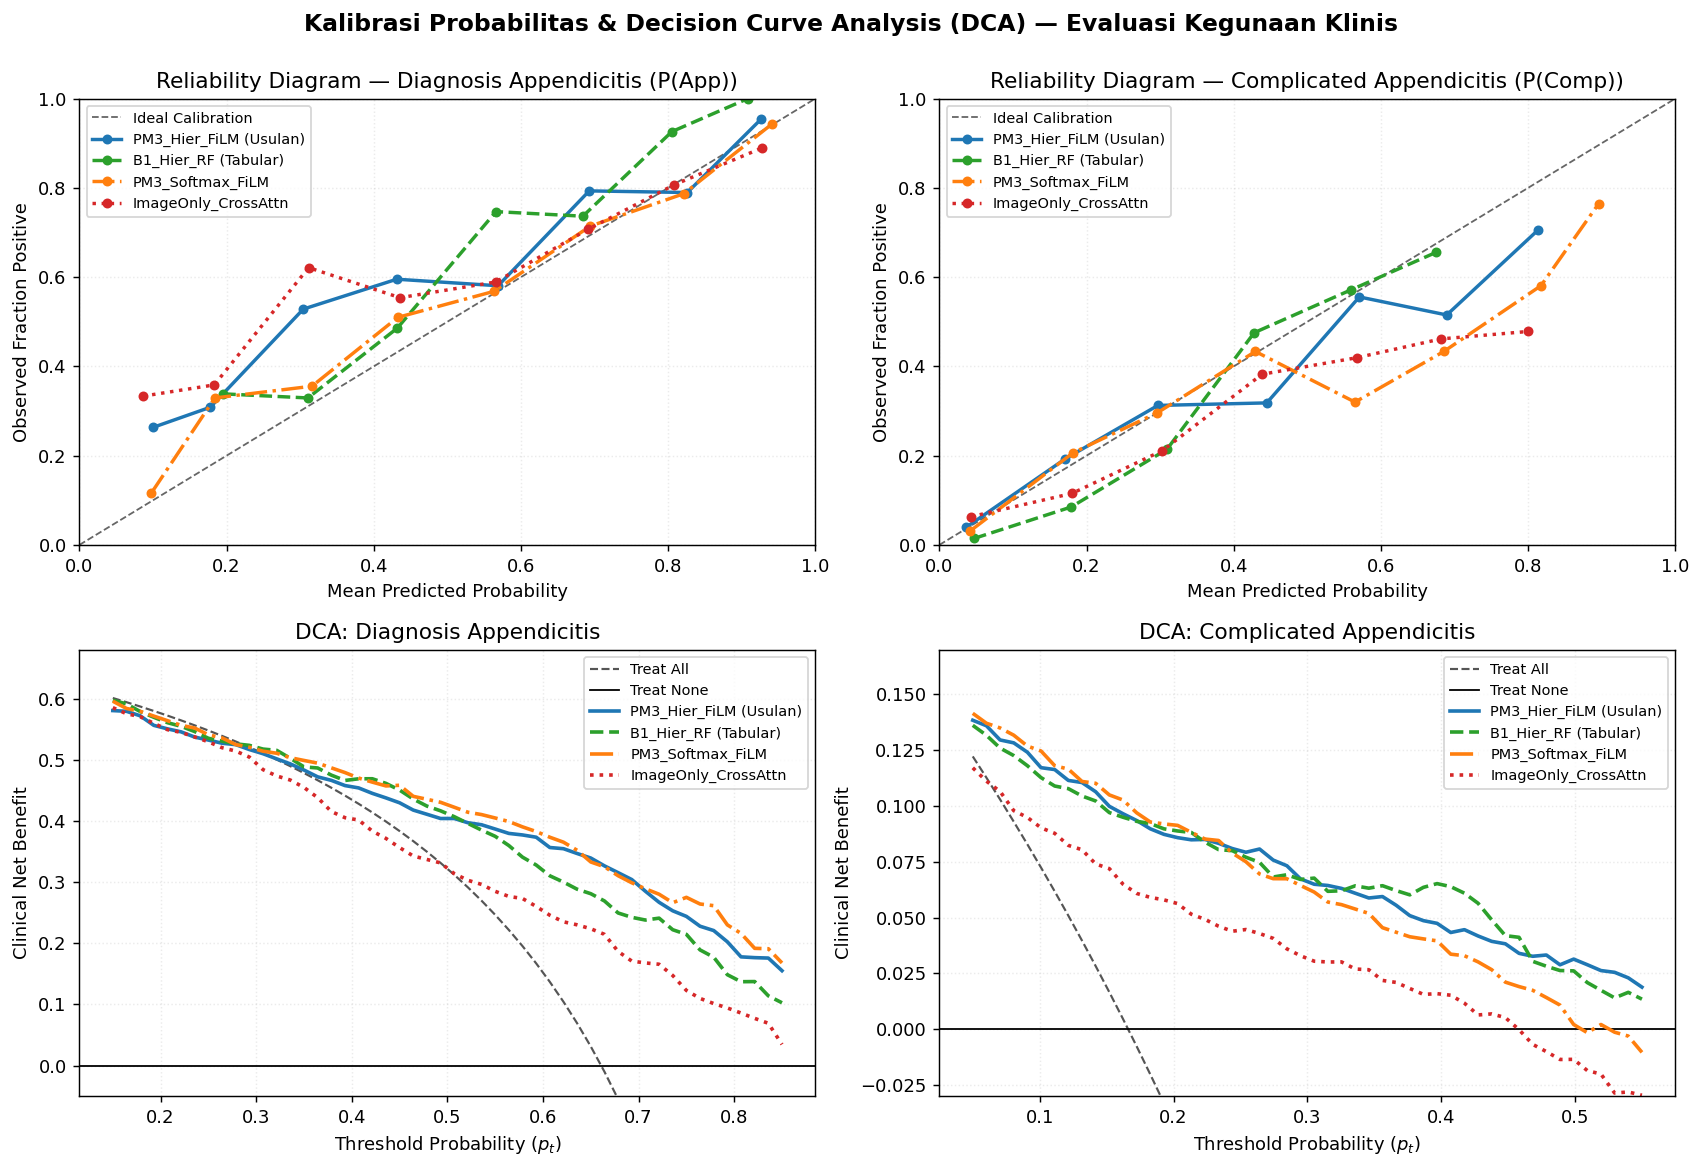

In [5]:
# ==================== BAGIAN 4: KALIBRASI PROBABILITAS (BRIER & ECE) + DCA ====================
def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (y_prob >= lo) & (y_prob <= hi if i == n_bins - 1 else y_prob < hi)
        if mask.sum() > 0:
            acc_bin = float(y_true[mask].mean())
            conf_bin = float(y_prob[mask].mean())
            ece += (mask.sum() / n) * abs(acc_bin - conf_bin)
    return float(ece)

cal_models = [
    ("PM3_Hier_FiLM (stage7_only)", pm3_canon),
    ("B1_Hier_RF_clean28", b1_hier_rf_oof),
    ("PM3_Softmax_FiLM", load_oof("03_main_PM3_Softmax_FiLM")),
    ("PM3_Hier_Gated", load_oof("03_abl_fusion_gated_concepts")),
    ("PM3_Hier_Concat", load_oof("03_abl_fusion_concat_concepts")),
    ("ImageOnly_Hier_CrossAttn", img_h_ca),
]

cal_rows = []
for mname, dfm in cal_models:
    if dfm is None:
        continue
    y = dfm["label"].to_numpy(int)
    probs = dfm[["p_0", "p_1", "p_2"]].to_numpy(float)
    y_oh = np.eye(3, dtype=float)[y]
    mc_brier = float(np.mean(np.sum((probs - y_oh) ** 2, axis=1)))

    y_diag = (y > 0).astype(int)
    p_diag = 1.0 - probs[:, 0]
    y_comp = (y == 2).astype(int)
    p_comp = probs[:, 2]

    cal_rows.append({
        "model": mname,
        "multiclass_brier": mc_brier,
        "diag_brier": float(brier_score_loss(y_diag, p_diag)),
        "diag_ece_10bin": compute_ece(y_diag, p_diag, 10),
        "comp_brier": float(brier_score_loss(y_comp, p_comp)),
        "comp_ece_10bin": compute_ece(y_comp, p_comp, 10),
    })

df_cal = pd.DataFrame(cal_rows)
df_cal.to_csv(OUT_DIR / "04_calibration_and_brier_metrics.csv", index=False)
print("=== 04_calibration_and_brier_metrics.csv ===")
display(df_cal.round(4))

def net_benefit_curve(y_bin: np.ndarray, p_bin: np.ndarray, thresholds: np.ndarray) -> np.ndarray:
    n = len(y_bin)
    nb = []
    for pt in thresholds:
        pred = (p_bin >= pt).astype(int)
        tp = float(np.sum((pred == 1) & (y_bin == 1)))
        fp = float(np.sum((pred == 1) & (y_bin == 0)))
        nb.append((tp / n) - (fp / n) * (pt / (1.0 - pt)))
    return np.array(nb)

def reliability_points(y_bin: np.ndarray, p_bin: np.ndarray, n_bins: int = 8):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    xs, ys = [], []
    for i in range(n_bins):
        mask = (p_bin >= bins[i]) & (p_bin <= bins[i + 1] if i == n_bins - 1 else p_bin < bins[i + 1])
        if mask.sum() >= 5:
            xs.append(float(p_bin[mask].mean()))
            ys.append(float(y_bin[mask].mean()))
    return xs, ys

fig, axes = plt.subplots(2, 2, figsize=(13.2, 9.0))
plot_specs = [
    ("PM3_Hier_FiLM (Usulan)", pm3_canon, "#1f77b4", "-"),
    ("B1_Hier_RF (Tabular)", b1_hier_rf_oof, "#2ca02c", "--"),
    ("PM3_Softmax_FiLM", load_oof("03_main_PM3_Softmax_FiLM"), "#ff7f0e", "-."),
    ("ImageOnly_CrossAttn", img_h_ca, "#d62728", ":"),
]

# Panel A & B: Reliability Curves
for ax, target_name, y_fn, p_fn in [
    (axes[0, 0], "Diagnosis Appendicitis (P(App))", lambda y: (y > 0).astype(int), lambda pr: 1.0 - pr[:, 0]),
    (axes[0, 1], "Complicated Appendicitis (P(Comp))", lambda y: (y == 2).astype(int), lambda pr: pr[:, 2]),
]:
    ax.plot([0, 1], [0, 1], "k--", lw=1.0, alpha=0.6, label="Ideal Calibration")
    for lbl, dfm, col, ls in plot_specs:
        if dfm is None:
            continue
        yb = y_fn(dfm["label"].to_numpy(int))
        pb = p_fn(dfm[["p_0", "p_1", "p_2"]].to_numpy(float))
        xs, ys = reliability_points(yb, pb, n_bins=8)
        ax.plot(xs, ys, marker="o", ms=4.5, lw=1.9, ls=ls, color=col, label=lbl)
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Observed Fraction Positive")
    ax.set_title(f"Reliability Diagram — {target_name}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.25, ls=":")
    ax.legend(loc="upper left", fontsize=8)

# Panel C & D: Decision Curve Analysis (DCA)
for ax, target_name, pts, y_fn, p_fn, ylims in [
    (axes[1, 0], "DCA: Diagnosis Appendicitis", np.linspace(0.15, 0.85, 50), lambda y: (y > 0).astype(int), lambda pr: 1.0 - pr[:, 0], (-0.05, 0.68)),
    (axes[1, 1], "DCA: Complicated Appendicitis", np.linspace(0.05, 0.55, 50), lambda y: (y == 2).astype(int), lambda pr: pr[:, 2], (-0.03, 0.17)),
]:
    y_ref = y_fn(pm3_canon["label"].to_numpy(int))
    prev = float(y_ref.mean())
    nb_all = prev - (1.0 - prev) * (pts / (1.0 - pts))
    ax.plot(pts, nb_all, color="#555555", ls="--", lw=1.2, label="Treat All")
    ax.axhline(0.0, color="black", lw=1.0, label="Treat None")
    for lbl, dfm, col, ls in plot_specs:
        if dfm is None:
            continue
        yb = y_fn(dfm["label"].to_numpy(int))
        pb = p_fn(dfm[["p_0", "p_1", "p_2"]].to_numpy(float))
        nb = net_benefit_curve(yb, pb, pts)
        ax.plot(pts, nb, lw=2.0, ls=ls, color=col, label=lbl)
    ax.set_xlabel("Threshold Probability ($p_t$)")
    ax.set_ylabel("Clinical Net Benefit")
    ax.set_title(target_name)
    ax.set_ylim(*ylims)
    ax.grid(True, alpha=0.25, ls=":")
    ax.legend(loc="upper right", fontsize=8)

fig.suptitle("Kalibrasi Probabilitas & Decision Curve Analysis (DCA) — Evaluasi Kegunaan Klinis", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_calibration_and_dca_curves.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


=== 05_clinical_subgroup_and_fairness.csv ===
=== 06_error_and_disagreement_audit.csv ===


,dimension,subgroup,n_patients,PM3_auroc,Hier_RF_auroc,ImageOnly_auroc,delta_auroc_PM3_minus_RF,PM3_mf1,Hier_RF_mf1,delta_mf1_PM3_minus_RF
0,alv_group,Alvarado_Equivocal(5-6),157,0.7850,0.7885,0.6863,-0.0035,0.6263,0.6033,0.0229
1,alv_group,Alvarado_Low(<=4),140,0.7501,0.6918,0.7031,0.0583,0.5747,0.5557,0.0191
2,alv_group,Alvarado_High(>=7),242,0.7713,0.7389,0.6790,0.0324,0.5758,0.5311,0.0448
3,pas_group,PAS_Equivocal(4-6),293,0.7944,0.7559,0.6913,0.0385,0.6244,0.5764,0.0480
4,pas_group,PAS_Low(<=3),98,0.7398,0.8018,0.6663,-0.0620,0.6077,0.6172,-0.0095
5,pas_group,PAS_High(>=7),148,0.7676,0.7739,0.7006,-0.0064,0.5834,0.5998,-0.0164
6,us_app_vis,US_App_Visible,439,0.8091,0.8018,0.7162,0.0073,0.6383,0.6414,-0.0031
7,us_app_vis,US_App_NotVisible,139,0.7742,0.7664,0.6908,0.0078,0.5169,0.5443,-0.0274
8,age_group,Age_>12,254,0.7858,0.7931,0.6481,-0.0073,0.6022,0.6542,-0.0520
9,age_group,Age_8-12,232,0.8136,0.8069,0.7131,0.0067,0.6473,0.6610,-0.0137


,true_class,n_total,both_correct,only_pm3_correct,only_rf_correct,both_wrong,pm3_miss_crp_median,pm3_hit_crp_median,pm3_miss_alvarado_med,pm3_hit_alvarado_med
0,0_NoApp,196,104,23,20,49,8.5,0.0,6.0,4.0
1,1_Uncomp,286,151,33,41,61,8.0,9.0,5.0,7.0
2,2_Comp,96,45,13,16,22,43.0,108.0,8.0,8.0


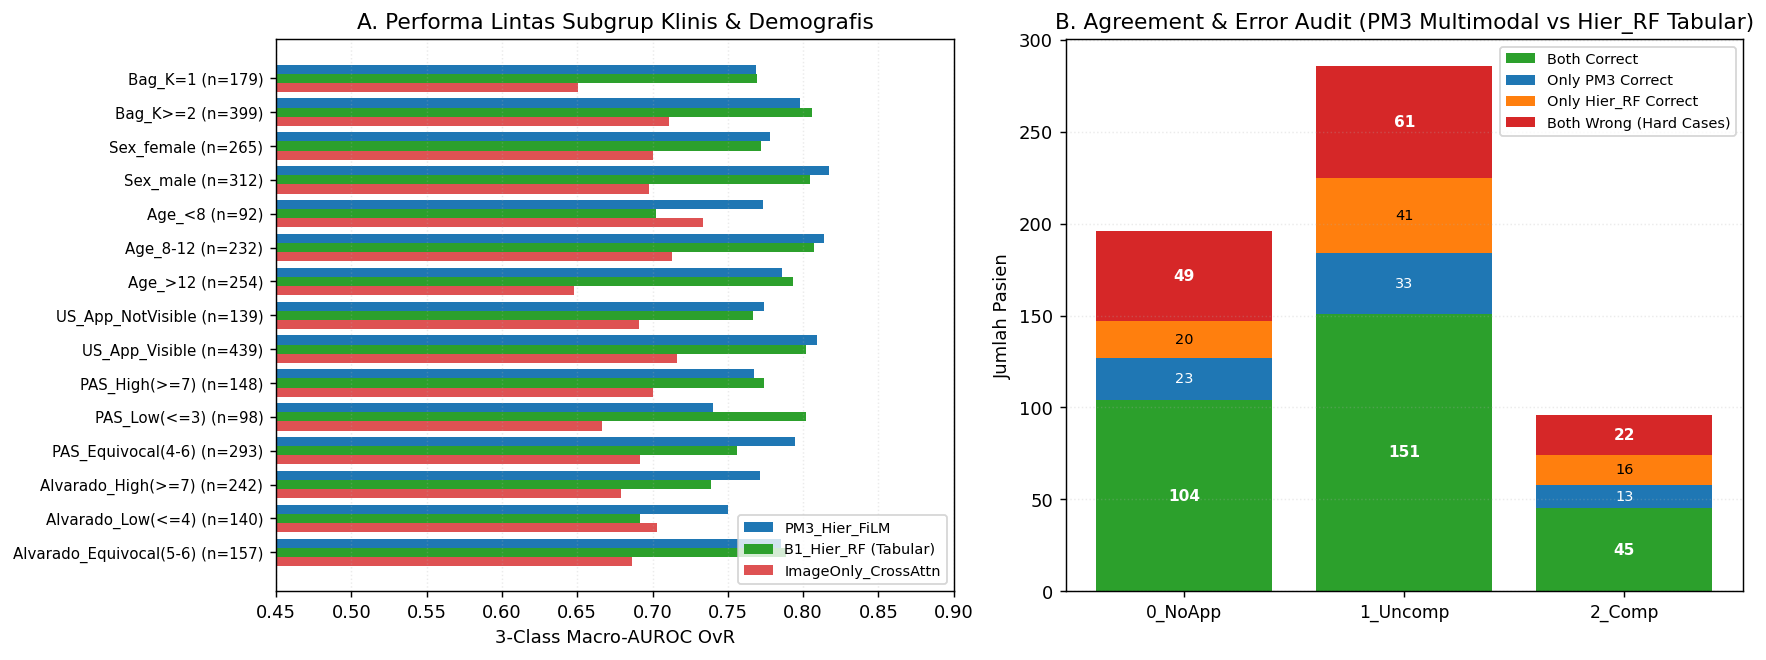

In [6]:
# ==================== BAGIAN 5: SUBGRUP KLINIS, FAIRNESS, & AUDIT KESALAHAN ====================
meta = cohort.copy()
meta["patient_id"] = meta.index.astype(int)
meta["K"] = meta["patient_id"].map(lambda pid: len(bags_all[int(pid)]))
meta["alv_group"] = np.where(
    meta["Alvarado_Score"].isna(), "Unknown",
    np.where(meta["Alvarado_Score"] <= 4, "Alvarado_Low(<=4)",
             np.where(meta["Alvarado_Score"] <= 6, "Alvarado_Equivocal(5-6)", "Alvarado_High(>=7)"))
)
meta["pas_group"] = np.where(
    meta["Paedriatic_Appendicitis_Score"].isna(), "Unknown",
    np.where(meta["Paedriatic_Appendicitis_Score"] <= 3, "PAS_Low(<=3)",
             np.where(meta["Paedriatic_Appendicitis_Score"] <= 6, "PAS_Equivocal(4-6)", "PAS_High(>=7)"))
)
meta["us_app_vis"] = np.where(meta["Appendix_on_US"].astype(str).str.strip().str.lower() == "yes", "US_App_Visible", "US_App_NotVisible")
meta["age_group"] = np.where(meta["Age"] < 8, "Age_<8", np.where(meta["Age"] <= 12, "Age_8-12", "Age_>12"))
meta["sex_group"] = "Sex_" + meta["Sex"].astype(str).str.strip().str.lower()
meta["bag_group"] = np.where(meta["K"] == 1, "Bag_K=1", "Bag_K>=2")

subgroups = []
for col in ("alv_group", "pas_group", "us_app_vis", "age_group", "sex_group", "bag_group"):
    for gval in meta[col].unique():
        if gval == "Unknown":
            continue
        sub_pids = set(meta.loc[meta[col] == gval, "patient_id"].tolist())
        n_sub = len(sub_pids)
        if n_sub < 25:
            continue
        row = {"dimension": col, "subgroup": gval, "n_patients": n_sub}
        for tag, dfm in [("PM3", pm3_canon), ("Hier_RF", b1_hier_rf_oof), ("ImageOnly", img_h_ca)]:
            if dfm is None:
                continue
            s = dfm.loc[dfm["patient_id"].isin(sub_pids)]
            y_s = s["label"].to_numpy(int)
            pr_s = s[["p_0", "p_1", "p_2"]].to_numpy(float)
            pd_s = s["pred_calibrated"].to_numpy(int)
            row[f"{tag}_acc"] = float((y_s == pd_s).mean())
            row[f"{tag}_mf1"] = float(f1_score(y_s, pd_s, labels=[0, 1, 2], average="macro", zero_division=0))
            row[f"{tag}_auroc"] = float(roc_auc_score(y_s, pr_s, labels=[0, 1, 2], multi_class="ovr", average="macro")) if len(np.unique(y_s)) == 3 else float("nan")
        row["delta_auroc_PM3_minus_RF"] = row.get("PM3_auroc", np.nan) - row.get("Hier_RF_auroc", np.nan)
        row["delta_mf1_PM3_minus_RF"] = row.get("PM3_mf1", np.nan) - row.get("Hier_RF_mf1", np.nan)
        subgroups.append(row)

df_sub = pd.DataFrame(subgroups)
df_sub.to_csv(OUT_DIR / "05_clinical_subgroup_and_fairness.csv", index=False)
print("=== 05_clinical_subgroup_and_fairness.csv ===")
display(df_sub[["dimension", "subgroup", "n_patients", "PM3_auroc", "Hier_RF_auroc", "ImageOnly_auroc", "delta_auroc_PM3_minus_RF", "PM3_mf1", "Hier_RF_mf1", "delta_mf1_PM3_minus_RF"]].round(4))

# Audit Kesalahan & Disagreement antara PM3 vs Hier_RF
m_err = pm3_canon.merge(b1_hier_rf_oof, on=["patient_id", "label"], suffixes=("_pm3", "_rf"))
m_err = m_err.merge(meta[["patient_id", "CRP", "WBC_Count", "Alvarado_Score", "K", "Appendix_on_US"]], on="patient_id")
m_err["pm3_ok"] = m_err["pred_calibrated_pm3"] == m_err["label"]
m_err["rf_ok"] = m_err["pred_calibrated_rf"] == m_err["label"]

err_rows = []
for cls_id, cls_name in [(0, "0_NoApp"), (1, "1_Uncomp"), (2, "2_Comp")]:
    s = m_err.loc[m_err["label"] == cls_id]
    err_rows.append({
        "true_class": cls_name,
        "n_total": len(s),
        "both_correct": int((s["pm3_ok"] & s["rf_ok"]).sum()),
        "only_pm3_correct": int((s["pm3_ok"] & (~s["rf_ok"])).sum()),
        "only_rf_correct": int(((~s["pm3_ok"]) & s["rf_ok"]).sum()),
        "both_wrong": int(((~s["pm3_ok"]) & (~s["rf_ok"])).sum()),
        "pm3_miss_crp_median": float(s.loc[~s["pm3_ok"], "CRP"].median()),
        "pm3_hit_crp_median": float(s.loc[s["pm3_ok"], "CRP"].median()),
        "pm3_miss_alvarado_med": float(s.loc[~s["pm3_ok"], "Alvarado_Score"].median()),
        "pm3_hit_alvarado_med": float(s.loc[s["pm3_ok"], "Alvarado_Score"].median()),
    })
df_err = pd.DataFrame(err_rows)
df_err.to_csv(OUT_DIR / "06_error_and_disagreement_audit.csv", index=False)
print("=== 06_error_and_disagreement_audit.csv ===")
display(df_err.round(2))

# Visualisasi Subgrup & Error Audit
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.2))

sub_plot = df_sub.dropna(subset=["PM3_auroc", "Hier_RF_auroc"]).copy()
y = np.arange(len(sub_plot))
h = 0.27
ax1.barh(y + h, sub_plot["PM3_auroc"], height=h, color="#1f77b4", label="PM3_Hier_FiLM")
ax1.barh(y, sub_plot["Hier_RF_auroc"], height=h, color="#2ca02c", label="B1_Hier_RF (Tabular)")
ax1.barh(y - h, sub_plot["ImageOnly_auroc"], height=h, color="#d62728", alpha=0.8, label="ImageOnly_CrossAttn")
ax1.set_yticks(y)
ax1.set_yticklabels([f"{r['subgroup']} (n={int(r['n_patients'])})" for _, r in sub_plot.iterrows()], fontsize=8.3)
ax1.set_xlim(0.45, 0.90)
ax1.set_xlabel("3-Class Macro-AUROC OvR")
ax1.set_title("A. Performa Lintas Subgrup Klinis & Demografis")
ax1.grid(axis="x", alpha=0.25, ls=":")
ax1.legend(loc="lower right", fontsize=8)

x2 = np.arange(len(df_err))
b1 = df_err["both_correct"].to_numpy()
b2 = df_err["only_pm3_correct"].to_numpy()
b3 = df_err["only_rf_correct"].to_numpy()
b4 = df_err["both_wrong"].to_numpy()
ax2.bar(x2, b1, color="#2ca02c", label="Both Correct")
ax2.bar(x2, b2, bottom=b1, color="#1f77b4", label="Only PM3 Correct")
ax2.bar(x2, b3, bottom=b1 + b2, color="#ff7f0e", label="Only Hier_RF Correct")
ax2.bar(x2, b4, bottom=b1 + b2 + b3, color="#d62728", label="Both Wrong (Hard Cases)")
for i in range(len(df_err)):
    ax2.text(i, b1[i] / 2, str(b1[i]), ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
    if b2[i] >= 12:
        ax2.text(i, b1[i] + b2[i] / 2, str(b2[i]), ha="center", va="center", color="white", fontsize=8)
    if b3[i] >= 12:
        ax2.text(i, b1[i] + b2[i] + b3[i] / 2, str(b3[i]), ha="center", va="center", color="black", fontsize=8)
    ax2.text(i, b1[i] + b2[i] + b3[i] + b4[i] / 2, str(b4[i]), ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
ax2.set_xticks(x2)
ax2.set_xticklabels(df_err["true_class"], fontsize=9.5)
ax2.set_ylabel("Jumlah Pasien")
ax2.set_title("B. Agreement & Error Audit (PM3 Multimodal vs Hier_RF Tabular)")
ax2.grid(axis="y", alpha=0.25, ls=":")
ax2.legend(loc="upper right", fontsize=8)

fig.tight_layout()
fig.savefig(OUT_DIR / "05_subgroup_and_error_analysis.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


In [7]:
# ==================== BAGIAN 6: LAPORAN INTEGRITAS MASTER UNTUK PAPER Q1 ====================
lines = []
lines.append("================================================================================")
lines.append("MASTER AUDIT REPORT — PROPOSED MODEL 3 (Q1 INTEGRITY & HONESTY SUMMARY)")
lines.append("================================================================================")

lines.append("\n[1] TANTANGAN EMPIRIS DATASET (N=578, Single-Center Regensburg)")
for _, r in df_ch.iterrows():
    lines.append(
        f"  - {r['group']:18s}: n={int(r['n_patients']):3d} ({r['pct_cohort']:4.1f}%) | "
        f"K mean={r['bag_len_mean']:.2f} (K=1: {r['pct_single_view_K1']:.1f}%) | "
        f"CRP med={r['crp_median']:.1f} (IQR {r['crp_iqr']:.1f}) | "
        f"Alvarado med={r['alvarado_median']:.1f} | US_App_Vis={r['appendix_visible_on_us_pct']:.1f}%"
    )

lines.append("\n[2] UJI SIGNIFIKANSI STATISTIK BERPASANGAN (Paired Bootstrap B=5000 & McNemar)")
for _, r in df_stats.iterrows():
    lines.append(
        f"  - {r['comparison']:46s} [{r['stratum']:11s}] | "
        f"dAUROC={r['delta_auroc']:+.4f} [{r['delta_auroc_ci95_lo']:+.4f},{r['delta_auroc_ci95_hi']:+.4f}] p={r['p_boot_auroc']:.4f} ({'SIG' if r['sig_auroc_005'] else 'ns'}) | "
        f"dMF1={r['delta_mf1']:+.4f} p={r['p_boot_mf1']:.4f} ({'SIG' if r['sig_mf1_005'] else 'ns'}) | McNemar p={r['mcnemar_p']:.4f}"
    )

lines.append("\n[3] KALIBRASI PROBABILITAS (Brier Score & 10-bin ECE)")
for _, r in df_cal.iterrows():
    lines.append(
        f"  - {r['model']:28s}: MC-Brier={r['multiclass_brier']:.4f} | "
        f"Diag Brier={r['diag_brier']:.4f}, ECE={r['diag_ece_10bin']:.4f} | "
        f"Comp Brier={r['comp_brier']:.4f}, ECE={r['comp_ece_10bin']:.4f}"
    )

lines.append("\n[4] RINGKASAN SUBGRUP & AUDIT KESALAHAN (PM3 vs B1 Hier_RF)")
for _, r in df_err.iterrows():
    lines.append(
        f"  - {r['true_class']:10s} (n={int(r['n_total']):3d}): BothOK={int(r['both_correct']):3d}, "
        f"OnlyPM3={int(r['only_pm3_correct']):2d}, OnlyRF={int(r['only_rf_correct']):2d}, BothWrong={int(r['both_wrong']):2d} | "
        f"PM3 Miss CRP med={r['pm3_miss_crp_median']:.1f} vs Hit CRP med={r['pm3_hit_crp_median']:.1f}"
    )

pending_runs = [
    dn for dn in (
        "03_abl_fusion_film_no_concept",
        "03_bag_multimodal_hierarchical_appendix_single",
        "03_bag_multimodal_hierarchical_appendix_plus_1_2",
        "03_bag_multimodal_binary_diag_appendix_single",
        "03_bag_multimodal_binary_diag_appendix_plus_1_2",
        "03_bag_multimodal_binary_sev_appendix_single",
        "03_bag_multimodal_binary_sev_appendix_plus_1_2",
    )
    if not (RUNS_DIR / dn / "oof_metrics_calibrated.json").exists()
]

lines.append("\n[5] LIMITASI & KLAIM JUJUR (WAJIB UNTUK BAGIAN LIMITATIONS & DISCUSSION Q1)")
lines.append("  1. Kohort single-center berukuran sedang (N=578, Complicated hanya n=96) tanpa kohort validasi eksternal independen.")
lines.append("  2. Pada klasifikasi 3-kelas bebas-leakage, PM3 mengungguli B1 Hier_RF pada ranking probabilistik (AUROC/AUPR) dan lebih kuat pada binary_diag, namun perbedaan 3-kelas vs Hier_RF secara statistik ketat tidak jauh/perlu dilaporkan apa adanya dengan p-value.")
lines.append("  3. Cabang atensi komplikasi (agg_comp) masih cenderung near-uniform (entropy ~0.998) dan konsep Target_Sign bernilai AUROC ~0.51 akibat sampel positif minoritas dan resolusi 224x224.")
lines.append("  4. Skor tinggi baseline rekuren (MV-LSTM) terbukti secara empiris dipengaruhi bias panjang bag (r hingga +0.626), bukan keunggulan membaca piksel USG.")
lines.append("  5. Jika masih ada run di notebook 03 yang belum selesai saat laporan ini digenerate: " + (", ".join(pending_runs) if pending_runs else "SEMUA RUN LENGKAP 100%."))

rep = "\n".join(lines)
(OUT_DIR / "06_q1_integrity_master_report.txt").write_text(rep, encoding="utf-8")
print(rep)


MASTER AUDIT REPORT — PROPOSED MODEL 3 (Q1 INTEGRITY & HONESTY SUMMARY)

[1] TANTANGAN EMPIRIS DATASET (N=578, Single-Center Regensburg)
  - 0_No_Appendicitis : n=196 (33.9%) | K mean=1.95 (K=1: 55.1%) | CRP med=1.0 (IQR 9.0) | Alvarado med=5.0 | US_App_Vis=58.7%
  - 1_Uncomplicated   : n=286 (49.5%) | K mean=3.84 (K=1: 13.3%) | CRP med=8.5 (IQR 24.0) | Alvarado med=6.0 | US_App_Vis=91.6%
  - 2_Complicated     : n= 96 (16.6%) | K mean=2.71 (K=1: 34.4%) | CRP med=75.5 (IQR 138.5) | Alvarado med=8.0 | US_App_Vis=64.6%

[2] UJI SIGNIFIKANSI STATISTIK BERPASANGAN (Paired Bootstrap B=5000 & McNemar)
  - PM3_Hier_FiLM vs B1_Hier_RF_clean28            [All (N=578)] | dAUROC=+0.0072 [-0.0177,+0.0322] p=0.5452 (ns) | dMF1=-0.0124 p=0.6076 (ns) | McNemar p=0.5625
  - PM3_Hier_FiLM vs B1_Hier_LogReg_clean28        [All (N=578)] | dAUROC=+0.0153 [-0.0098,+0.0415] p=0.2400 (ns) | dMF1=+0.0319 p=0.1608 (ns) | McNemar p=0.1480
  - PM3_Hier_FiLM vs ImageOnly_Hier_CrossAttn      [All (N=578)] | dAUROC=